# RQ4b-3 applicant-sex supplementary results

This presentation-only notebook reports the accepted supplementary run `rq4b3_sex_supplementary_20261024_02`. It reads published CSV and JSON artifacts only. It does not read raw data, split files, predictions, models, preprocessors, or bootstrap indices; it does not fit, infer, select thresholds, regenerate bootstrap samples, or recompute metrics.

The protected attribute is `applicant_sex`, using the same RQ3 mapping used by RQ3 and RQ4a. Sex EOD uses the fixed Male/Female roster. The other three mapped labels remain visible for coverage and per-group reporting.

## TL;DR

The package contains nine RQ4b arms, six same-seed comparisons against lambda 0, 1,000 paired Test bootstrap replicates per comparison, all five mapped applicant-sex groups, three across-seed summaries, and nine Validation-to-Test sex-EOD gaps. Execution status, metric values, and research interpretation are kept separate. No automated effectiveness or policy conclusion is made here.

## 1. Setup and locked source

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
pd.set_option("display.precision", 8)

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "AGENTS.md").exists())
RUN_ID = "rq4b3_sex_supplementary_20261024_02"
RUN_DIR = project_root / "artifacts/dataset_b/rq4/rq4b/sex_supplementary" / RUN_ID
EVAL_STAGE = RUN_DIR / "stages/sex_evaluation"
PACKAGE_STAGE = RUN_DIR / "stages/package_validation"
EXPECTED_MANIFEST_SHA256 = "30bff0c015d1295c7cf796bdb50e4e0a92ce5c10d34350885fd1517ad150d550"
EXPECTED_EVALUATION_RECEIPT_SHA256 = "5e721ba5e8ac9be0f5ad25d1b12d5699c81227b4cdac232fe92a3cb9be96b622"
EXPECTED_PACKAGE_RECEIPT_SHA256 = "0986636547f0f69dbd545dabb9bca8340839a2d7fe64c39e0c9be684aa044a16"
PRIMARY_GROUPS = ["Male", "Female"]
ALL_GROUPS = ["Male", "Female", "Information not provided", "Not applicable", "Applicant selected both male and female"]
REPLICATED_LAMBDAS = [0.0, 0.01]
SEEDS = [42, 43, 44]

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def read_table(name):
    return pd.read_csv(EVAL_STAGE / name, float_precision="round_trip")

print(f"Project root: {project_root}")
print(f"Supplementary run: {RUN_ID}")

Project root: d:\Proj\DAP\DAP391m_GR12
Supplementary run: rq4b3_sex_supplementary_20261024_02


## 2. Package integrity and lineage

In [2]:
manifest_path = RUN_DIR / "run_manifest.json"
evaluation_receipt_path = EVAL_STAGE / "receipt.json"
package_receipt_path = PACKAGE_STAGE / "receipt.json"
manifest = read_json(manifest_path)
evaluation_receipt = read_json(evaluation_receipt_path)
package_receipt = read_json(package_receipt_path)
package_report = read_json(PACKAGE_STAGE / "package_report.json")
execution_status = read_json(EVAL_STAGE / "execution_status.json")

root_hashes = pd.DataFrame([
    {"artifact": "run_manifest.json", "observed_sha256": sha256(manifest_path), "locked_sha256": EXPECTED_MANIFEST_SHA256},
    {"artifact": "sex_evaluation/receipt.json", "observed_sha256": sha256(evaluation_receipt_path), "locked_sha256": EXPECTED_EVALUATION_RECEIPT_SHA256},
    {"artifact": "package_validation/receipt.json", "observed_sha256": sha256(package_receipt_path), "locked_sha256": EXPECTED_PACKAGE_RECEIPT_SHA256},
])
root_hashes["matches"] = root_hashes["observed_sha256"] == root_hashes["locked_sha256"]
display(root_hashes)
assert root_hashes["matches"].all(), "A locked root artifact differs."

def verify_stage(stage_dir, receipt):
    present = {path.name for path in stage_dir.iterdir()} - {"receipt.json"}
    expected = set(receipt["outputs"])
    assert present == expected, f"Stage roster differs: missing={sorted(expected-present)}, extra={sorted(present-expected)}"
    return pd.DataFrame([
        {"file": name, "sha256": sha256(stage_dir / name), "receipt_sha256": digest, "matches": sha256(stage_dir / name) == digest}
        for name, digest in sorted(receipt["outputs"].items())
    ])

evaluation_integrity = verify_stage(EVAL_STAGE, evaluation_receipt)
package_integrity = verify_stage(PACKAGE_STAGE, package_receipt)
display(evaluation_integrity)
display(package_integrity)
assert evaluation_integrity["matches"].all() and package_integrity["matches"].all()
assert package_receipt["inputs"]["sex_evaluation"] == sha256(evaluation_receipt_path)

source_pins = pd.DataFrame([{"pin": key, "sha256": value} for key, value in manifest["source_pins"].items()])
display(source_pins)

,artifact,observed_sha256,locked_sha256,matches
0,run_manifest.json,30bff0c015d1295c7cf796bdb50e4e0a92ce5c10d34350...,30bff0c015d1295c7cf796bdb50e4e0a92ce5c10d34350...,True
1,sex_evaluation/receipt.json,5e721ba5e8ac9be0f5ad25d1b12d5699c81227b4cdac23...,5e721ba5e8ac9be0f5ad25d1b12d5699c81227b4cdac23...,True
2,package_validation/receipt.json,0986636547f0f69dbd545dabb9bca8340839a2d7fe64c3...,0986636547f0f69dbd545dabb9bca8340839a2d7fe64c3...,True


,file,sha256,receipt_sha256,matches
0,execution_status.json,512ca52db42da4a66c1dd5cad611405981482e44a6d93d...,512ca52db42da4a66c1dd5cad611405981482e44a6d93d...,True
1,sex_across_seed_summary.csv,a915ad95eb044039c18e0281c344c042a2685c5d09e28c...,a915ad95eb044039c18e0281c344c042a2685c5d09e28c...,True
2,sex_arm_metrics.csv,8b0efe74e00d669fc666c338d4ee641cbc93d6f03f8a0e...,8b0efe74e00d669fc666c338d4ee641cbc93d6f03f8a0e...,True
3,sex_bootstrap_replicates.csv,863d356f4a69a32d8f698966b4a0659f866bce5bfa1da8...,863d356f4a69a32d8f698966b4a0659f866bce5bfa1da8...,True
4,sex_bootstrap_summary.csv,be4587614bd445aa69b782495a24ccbe6ec307ef7ef995...,be4587614bd445aa69b782495a24ccbe6ec307ef7ef995...,True
5,sex_decision_changes.csv,585c214c746dc4fda847826bdf64111ac0ae9e86674abf...,585c214c746dc4fda847826bdf64111ac0ae9e86674abf...,True
6,sex_generalization_gaps.csv,3ad5722e64e6a89bc2ea8df4a20a1e94a456f344a55606...,3ad5722e64e6a89bc2ea8df4a20a1e94a456f344a55606...,True
7,sex_group_metrics.csv,615138fb73160fa1002c0c1956191d1eda2eeea7db7e34...,615138fb73160fa1002c0c1956191d1eda2eeea7db7e34...,True
8,sex_matched_deltas.csv,6be048e8405738eafa22c2234124d0a495c05a7fe4e278...,6be048e8405738eafa22c2234124d0a495c05a7fe4e278...,True


,file,sha256,receipt_sha256,matches
0,package_report.json,296690d7b0c4b57dad2f338d39dfdebfc8146860d82c79...,296690d7b0c4b57dad2f338d39dfdebfc8146860d82c79...,True


,pin,sha256
0,gate_c_manifest,5d072d7ff094817b8a281d2ea5b6527682678f97d09fa5...
1,gate_c_receipt,14f602bb0ef59d7cbfb22e8b5fbdaf6604e5a90c295370...
2,gate_c_selection,76af4d077ea9febbb8865008c6d566923ddb66e88f5026...
3,locked_bootstrap,2ee377b6fbae8a3a6453a7d8f2f4a0a3f1ce61374f1258...
4,source_manifest:rq4b3_adv_20261019_02,b84f5d018cd308a97d0918dd9ba336e8f449a8b5c16a7c...
5,source_manifest:rq4b3_adv_20261021_01,315bd175e1239230992c459fb937f8de9ca4f995527a5e...
6,source_manifest:rq4b3_adv_20261022_01,f6ebf429d4d0a5ec2b4abd08e247a6afa75b381da2da38...
7,source_package_receipt,d20fa9b13cd4f9b9e5e52e4c387f49a63791f4c95af3fa...
8,source_receipt:rq4b3_adv_20261019_02:stages/de...,0734ace391cee86112039640a5b6cc6c7c63a98e0da63c...
9,source_receipt:rq4b3_adv_20261019_02:stages/de...,2fbf721f352fef151c00e512e288223411d04b48f84a19...


## 3. Execution status and output inventory

In [3]:
display(pd.Series(execution_status, name="sex_evaluation").to_frame())
display(pd.Series(package_report, name="package_validation").to_frame())

assert manifest["sex_attribute"] == "applicant_sex"
assert manifest["primary_roster"] == PRIMARY_GROUPS
assert manifest["coverage_groups"] == ALL_GROUPS
assert evaluation_receipt["status"] == package_receipt["status"] == "PASS"
assert execution_status == {
    "cv_fit_count": 0, "execution_status": "completed", "fit_count": 0,
    "inference_performed": False, "refit_count": 0, "research_interpretation_owner": "user"
}
assert package_report["recomputed_from_saved_predictions"] is True
assert package_report["inference_performed"] is False

tables = {name: read_table(name) for name in manifest["output_schema"]}
inventory = pd.DataFrame([{"table": name, "rows": len(frame), "columns": len(frame.columns)} for name, frame in tables.items()])
display(inventory)

,sex_evaluation
cv_fit_count,0
execution_status,completed
fit_count,0
inference_performed,False
refit_count,0
research_interpretation_owner,user


,package_validation
execution_status,completed
inference_performed,False
local_fit_counts,"{'cv_fold_fits': 0, 'refit_fits': 0}"
recomputed_from_saved_predictions,True
verified_outputs,"[sex_arm_metrics.csv, sex_group_metrics.csv, s..."


,table,rows,columns
0,sex_across_seed_summary.csv,3,12
1,sex_arm_metrics.csv,18,13
2,sex_bootstrap_replicates.csv,6000,8
3,sex_bootstrap_summary.csv,6,11
4,sex_decision_changes.csv,36,11
5,sex_generalization_gaps.csv,9,8
6,sex_group_metrics.csv,90,16
7,sex_matched_deltas.csv,6,6


## 4. Per-arm applicant-sex EOD

Sex EOD is the maximum of the Male/Female TPR range and FPR range. Values below are stored outputs; smaller or larger values are not assigned an automated research label.

,partition,adversary_lambda,seed,role,threshold,rows,sex_eod,tpr_range,fpr_range,sex_eod_valid
0,test,0.00,42,gate_c_selected_control,0.763,43996,0.03078250,0.00433115,0.03078250,True
1,test,0.00,43,gate_c_selected_control,0.766,43996,0.03163303,0.00608346,0.03163303,True
2,test,0.00,44,gate_c_selected_control,0.753,43996,0.03257484,0.00319887,0.03257484,True
3,test,0.01,42,user_requested_comparator,0.750,43996,0.02834933,0.00414867,0.02834933,True
4,test,0.01,43,user_requested_comparator,0.754,43996,0.02730785,0.00519193,0.02730785,True
5,test,0.01,44,user_requested_comparator,0.766,43996,0.03064398,0.00581431,0.03064398,True
6,test,0.03,42,user_requested_screening,0.741,43996,0.03758810,0.00474564,0.03758810,True
7,test,0.10,42,user_requested_screening,0.738,43996,0.03556111,0.00146284,0.03556111,True
8,test,0.30,42,user_requested_screening,0.836,43996,0.03178191,0.00945530,0.03178191,True
9,validation,0.00,42,gate_c_selected_control,0.763,43995,0.03156082,0.00358229,0.03156082,True


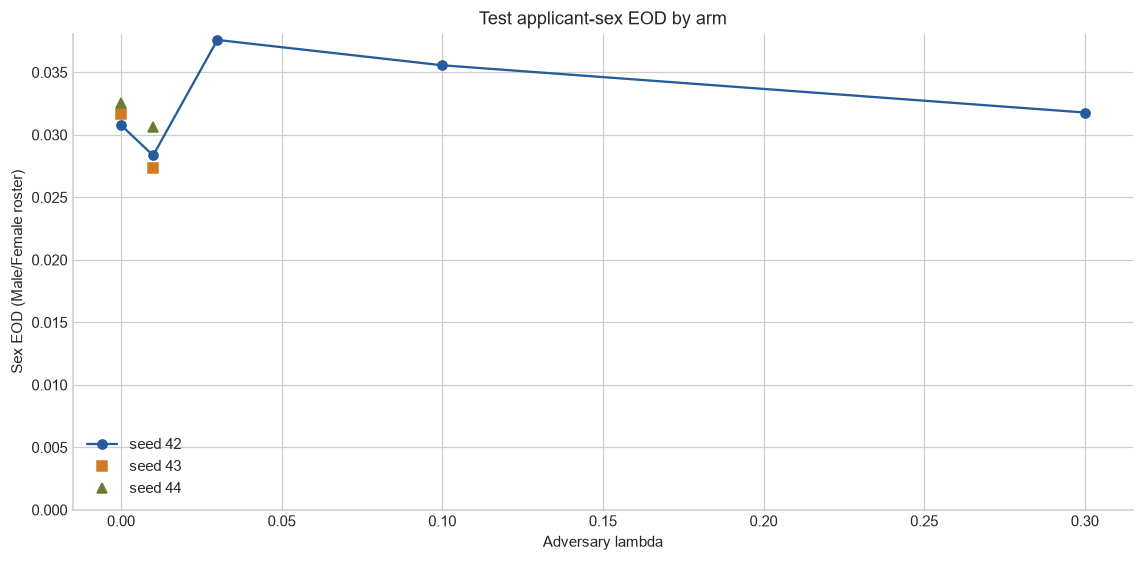

In [4]:
arm_metrics = tables["sex_arm_metrics.csv"].copy()
arm_metrics = arm_metrics.sort_values(["partition", "adversary_lambda", "seed"]).reset_index(drop=True)
display(arm_metrics[["partition", "adversary_lambda", "seed", "role", "threshold", "rows", "sex_eod", "tpr_range", "fpr_range", "sex_eod_valid"]])

test_arms = arm_metrics[arm_metrics["partition"] == "test"].copy()
fig, ax = plt.subplots(figsize=(10.5, 5.2))
palette = {42: "#255C99", 43: "#D17A22", 44: "#6B7D32"}
markers = {42: "o", 43: "s", 44: "^"}
for seed in SEEDS:
    frame = test_arms[test_arms["seed"] == seed].sort_values("adversary_lambda")
    ax.plot(frame["adversary_lambda"], frame["sex_eod"], marker=markers[seed], color=palette[seed],
            linestyle="-" if seed == 42 else "none", label=f"seed {seed}")
ax.set(title="Test applicant-sex EOD by arm", xlabel="Adversary lambda", ylabel="Sex EOD (Male/Female roster)")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Per-group rates and counts

All five mapped groups remain in the tables. EOD itself uses only Male and Female. Undefined component rates remain missing rather than being replaced by zero.

,adversary_lambda,seed,group,row_count,actual_approved_count,actual_denied_count,predicted_approved_count,predicted_denied_count,tpr_approved,fpr_approved,selection_rate,invalid_reason
0,0.00,42,Male,24799,18607,6192,17805,6994,0.85629064,0.30232558,0.71797250,NaN
1,0.00,42,Female,15347,11355,3992,10758,4589,0.85195949,0.27154309,0.70098391,NaN
2,0.00,42,Information not provided,2384,1662,722,1568,816,0.83032491,0.26038781,0.65771812,NaN
3,0.00,42,Not applicable,1439,1176,263,1172,267,0.93112245,0.29277567,0.81445448,NaN
4,0.00,42,Applicant selected both male and female,27,15,12,17,10,NaN,NaN,NaN,undefined_insufficient_actual_approved|undefin...
5,0.00,43,Male,24799,18607,6192,17777,7022,0.85575321,0.29941860,0.71684342,NaN
6,0.00,43,Female,15347,11355,3992,10717,4630,0.84966975,0.26778557,0.69831237,NaN
7,0.00,43,Information not provided,2384,1662,722,1568,816,0.82912154,0.26315789,0.65771812,NaN
8,0.00,43,Not applicable,1439,1176,263,1165,274,0.92602041,0.28897338,0.80958999,NaN
9,0.00,43,Applicant selected both male and female,27,15,12,17,10,NaN,NaN,NaN,undefined_insufficient_actual_approved|undefin...


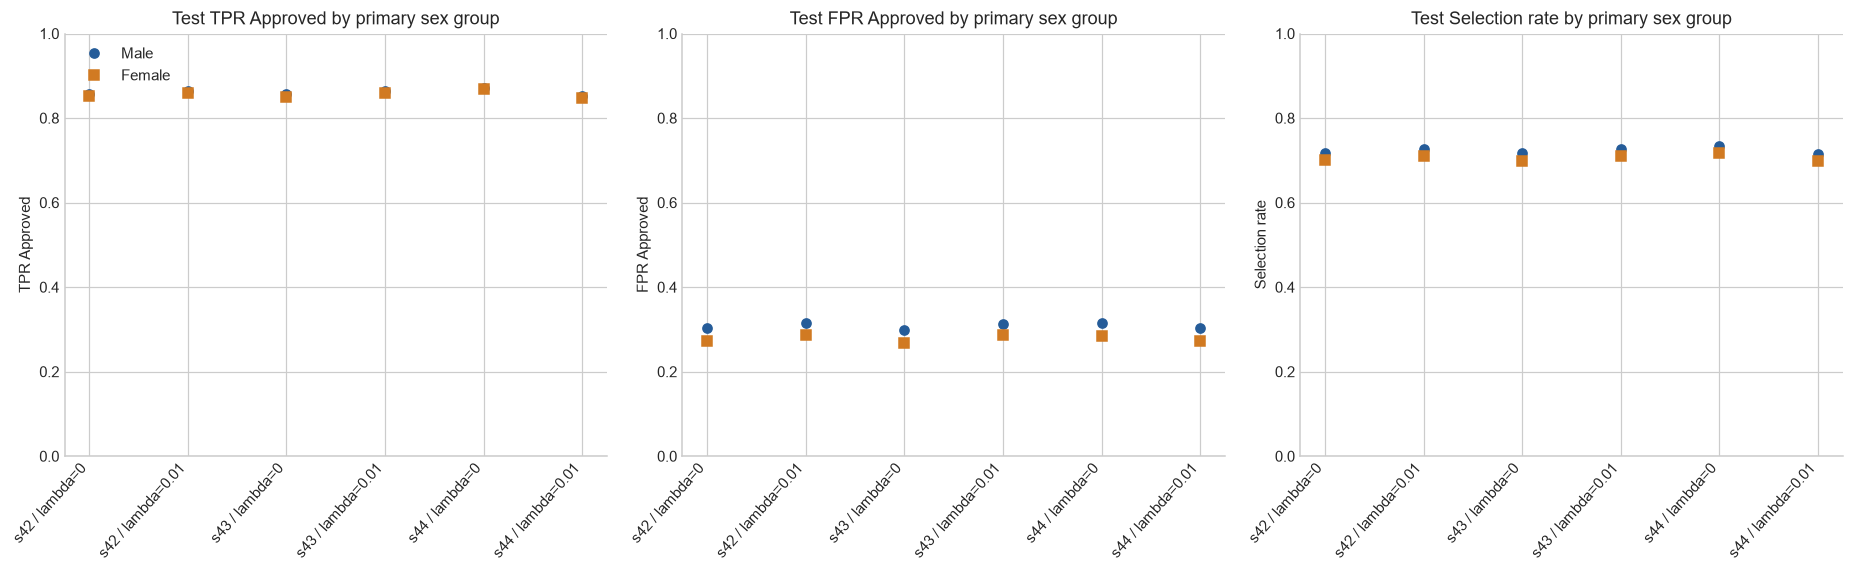

In [5]:
group_metrics = tables["sex_group_metrics.csv"].copy()
test_groups = group_metrics[group_metrics["partition"] == "test"].copy()
test_groups["group"] = pd.Categorical(test_groups["group"], categories=ALL_GROUPS, ordered=True)
test_groups = test_groups.sort_values(["adversary_lambda", "seed", "group"]).reset_index(drop=True)
display(test_groups[["adversary_lambda", "seed", "group", "row_count", "actual_approved_count", "actual_denied_count", "predicted_approved_count", "predicted_denied_count", "tpr_approved", "fpr_approved", "selection_rate", "invalid_reason"]])

primary = test_groups[test_groups["group"].isin(PRIMARY_GROUPS) & test_groups["adversary_lambda"].isin(REPLICATED_LAMBDAS)].copy()
primary["arm"] = primary.apply(lambda row: f"s{int(row.seed)} / lambda={row.adversary_lambda:g}", axis=1)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3), sharex=True)
metric_specs = [("tpr_approved", "TPR Approved"), ("fpr_approved", "FPR Approved"), ("selection_rate", "Selection rate")]
group_style = {"Male": ("#255C99", "o"), "Female": ("#D17A22", "s")}
arm_order = [f"s{seed} / lambda={lam:g}" for seed in SEEDS for lam in REPLICATED_LAMBDAS]
for ax, (metric, label) in zip(axes, metric_specs):
    for group in PRIMARY_GROUPS:
        frame = primary[primary["group"] == group].set_index("arm").reindex(arm_order)
        color, marker = group_style[group]
        ax.plot(range(len(arm_order)), frame[metric], marker=marker, linestyle="none", color=color, label=group)
    ax.set_title(f"Test {label} by primary sex group")
    ax.set_ylabel(label)
    ax.set_xticks(range(len(arm_order)), arm_order, rotation=48, ha="right")
    ax.set_ylim(0, 1)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Matched deltas and paired-bootstrap intervals

Each comparator is paired with lambda 0 at the same seed. `delta_sex_eod` is comparator minus control. The intervals are stored 95% percentile intervals from the locked paired Test bootstrap indices.

,seed,comparator_lambda,control_lambda,delta_sex_eod,lower,upper,valid_replicates,invalid_replicates,quantile_method
0,42,0.01,0.0,-0.00243316,-0.01094943,0.00591392,1000,0,linear
1,42,0.03,0.0,0.00680560,-0.00605979,0.02132426,1000,0,linear
2,42,0.10,0.0,0.00477861,-0.00817851,0.01909628,1000,0,linear
3,42,0.30,0.0,0.00099941,-0.01273939,0.01455586,1000,0,linear
4,43,0.01,0.0,-0.00432519,-0.01185919,0.00382731,1000,0,linear
5,44,0.01,0.0,-0.00193086,-0.01032118,0.00622717,1000,0,linear


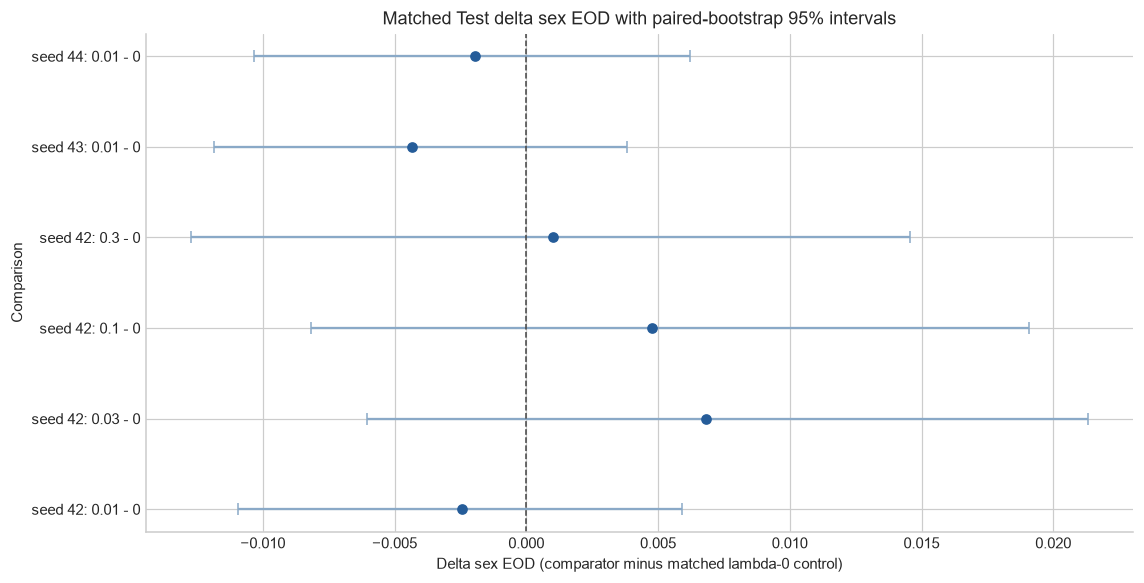

In [6]:
matched = tables["sex_matched_deltas.csv"].copy()
bootstrap = tables["sex_bootstrap_summary.csv"].copy()
comparisons = matched.merge(bootstrap, on=["seed", "comparator_lambda", "control_lambda"], validate="one_to_one")
comparisons["comparison"] = comparisons.apply(lambda row: f"seed {int(row.seed)}: {row.comparator_lambda:g} - {row.control_lambda:g}", axis=1)
display(comparisons[["seed", "comparator_lambda", "control_lambda", "delta_sex_eod", "lower", "upper", "valid_replicates", "invalid_replicates", "quantile_method"]])

plot_frame = comparisons.sort_values(["seed", "comparator_lambda"]).reset_index(drop=True)
xerr = np.vstack([plot_frame["delta_sex_eod"] - plot_frame["lower"], plot_frame["upper"] - plot_frame["delta_sex_eod"]])
fig, ax = plt.subplots(figsize=(10.5, 5.4))
positions = np.arange(len(plot_frame))
ax.errorbar(plot_frame["delta_sex_eod"], positions, xerr=xerr, fmt="o", color="#255C99", ecolor="#8AA9C7", capsize=4)
ax.axvline(0, color="#444444", linewidth=1, linestyle="--")
ax.set_yticks(positions, plot_frame["comparison"])
ax.set(title="Matched Test delta sex EOD with paired-bootstrap 95% intervals", xlabel="Delta sex EOD (comparator minus matched lambda-0 control)", ylabel="Comparison")
plt.tight_layout()
plt.show()

### Bootstrap replicate evidence

In [7]:
bootstrap_replicates = tables["sex_bootstrap_replicates.csv"]
replicate_audit = bootstrap_replicates.groupby(["seed", "comparator_lambda"], as_index=False).agg(
    replicates=("replicate_id", "size"),
    unique_replicate_ids=("replicate_id", "nunique"),
    sample_size=("sample_size", "first"),
    valid_replicates=("valid", "sum"),
    minimum_delta=("delta_sex_eod", "min"),
    maximum_delta=("delta_sex_eod", "max"),
)
display(replicate_audit)

,seed,comparator_lambda,replicates,unique_replicate_ids,sample_size,valid_replicates,minimum_delta,maximum_delta
0,42,0.01,1000,1000,43996,1000,-0.01529985,0.00992535
1,42,0.03,1000,1000,43996,1000,-0.01537719,0.02881937
2,42,0.10,1000,1000,43996,1000,-0.01733894,0.02710147
3,42,0.30,1000,1000,43996,1000,-0.01974185,0.02327525
4,43,0.01,1000,1000,43996,1000,-0.01620151,0.00855885
5,44,0.01,1000,1000,43996,1000,-0.01442388,0.01269831


## 7. Decision changes overall and by sex group

,seed,comparator_lambda,control_lambda,scope,group,row_count,unchanged_count,changed_count,denied_to_approved_count,approved_to_denied_count,change_rate
0,42,0.01,0.0,overall,__all__,43996,42110,1886,1157,729,0.04286753
1,42,0.03,0.0,overall,__all__,43996,39304,4692,3108,1584,0.10664606
2,42,0.10,0.0,overall,__all__,43996,39182,4814,3148,1666,0.10941904
3,42,0.30,0.0,overall,__all__,43996,39329,4667,2595,2072,0.10607783
4,43,0.01,0.0,overall,__all__,43996,42205,1791,1118,673,0.04070825
5,44,0.01,0.0,overall,__all__,43996,41963,2033,637,1396,0.04620875


,seed,comparator_lambda,control_lambda,scope,group,row_count,unchanged_count,changed_count,denied_to_approved_count,approved_to_denied_count,change_rate
5,42,0.01,0.0,sex_group,Applicant selected both male and female,27,26,1,1,0,0.03703704
2,42,0.01,0.0,sex_group,Female,15347,14678,669,411,258,0.04359158
3,42,0.01,0.0,sex_group,Information not provided,2384,2274,110,75,35,0.04614094
1,42,0.01,0.0,sex_group,Male,24799,23726,1073,650,423,0.04326787
4,42,0.01,0.0,sex_group,Not applicable,1439,1406,33,20,13,0.02293259
11,42,0.03,0.0,sex_group,Applicant selected both male and female,27,23,4,4,0,0.14814815
8,42,0.03,0.0,sex_group,Female,15347,13805,1542,1073,469,0.10047566
9,42,0.03,0.0,sex_group,Information not provided,2384,2122,262,195,67,0.10989933
7,42,0.03,0.0,sex_group,Male,24799,22156,2643,1829,814,0.10657688
10,42,0.03,0.0,sex_group,Not applicable,1439,1198,241,7,234,0.16747741


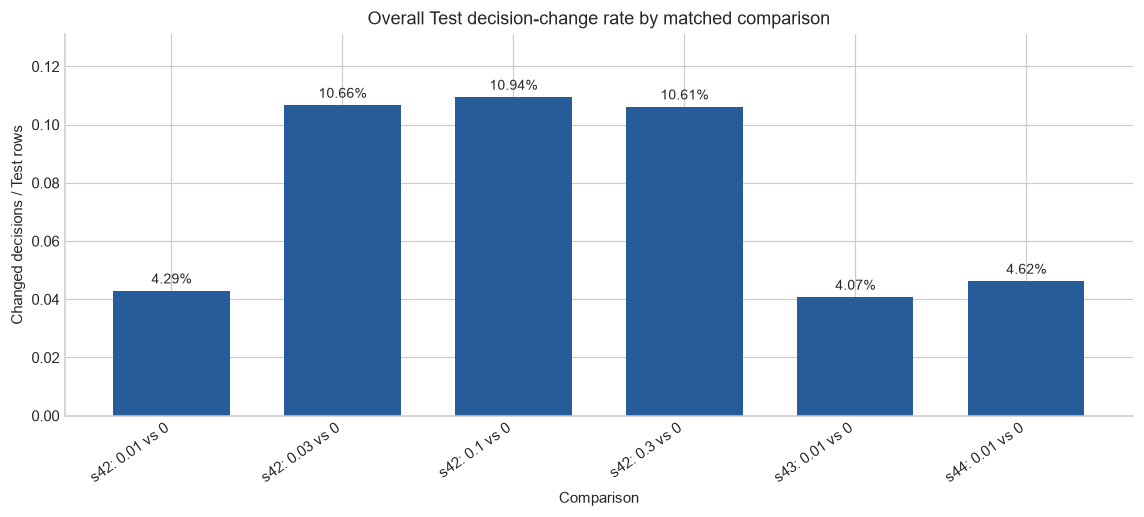

In [8]:
decision_changes = tables["sex_decision_changes.csv"].copy()
overall_changes = decision_changes[decision_changes["scope"] == "overall"].sort_values(["seed", "comparator_lambda"]).reset_index(drop=True)
group_changes = decision_changes[decision_changes["scope"] == "sex_group"].copy()
display(overall_changes)
display(group_changes.sort_values(["seed", "comparator_lambda", "group"]))

overall_changes["comparison"] = overall_changes.apply(lambda row: f"s{int(row.seed)}: {row.comparator_lambda:g} vs 0", axis=1)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
bars = ax.bar(overall_changes["comparison"], overall_changes["change_rate"], color="#255C99", width=0.68)
ax.bar_label(bars, labels=[f"{value:.2%}" for value in overall_changes["change_rate"]], padding=3, fontsize=9)
ax.set(title="Overall Test decision-change rate by matched comparison", xlabel="Comparison", ylabel="Changed decisions / Test rows")
ax.set_ylim(0, max(overall_changes["change_rate"]) * 1.2)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 8. Across-seed summaries

Across-seed summaries use seeds 42, 43, and 44 only for lambda 0, lambda 0.01, and their matched delta. Screening arms remain single-seed outputs.

In [9]:
across_seed = tables["sex_across_seed_summary.csv"].copy()
display(across_seed)

,scope,adversary_lambda,comparator_lambda,control_lambda,quantity,seed_count,mean,standard_deviation,ddof,min,max,range
0,per_arm,0.00,NaN,NaN,sex_eod,3,0.03166346,0.00089656,1,0.03078250,0.03257484,0.00179234
1,per_arm,0.01,NaN,NaN,sex_eod,3,0.02876705,0.00170684,1,0.02730785,0.03064398,0.00333613
2,matched_delta,NaN,0.01,0.0,delta_sex_eod,3,-0.00289640,0.00126259,1,-0.00432519,-0.00193086,0.00239432


## 9. Validation-to-Test generalization gaps

The stored gap is Test sex EOD minus Validation sex EOD at the arm's locked threshold. It is descriptive and receives no automatic interpretation.

,seed,adversary_lambda,quantity,validation_value,test_value,test_minus_validation,valid,invalid_reason
0,42,0.00,sex_eod,0.03156082,0.03078250,-0.00077832,True,NaN
1,42,0.01,sex_eod,0.03030759,0.02834933,-0.00195825,True,NaN
2,42,0.03,sex_eod,0.03544221,0.03758810,0.00214588,True,NaN
3,42,0.10,sex_eod,0.02633434,0.03556111,0.00922677,True,NaN
4,42,0.30,sex_eod,0.03157110,0.03178191,0.00021081,True,NaN
5,43,0.00,sex_eod,0.02420904,0.03163303,0.00742399,True,NaN
6,43,0.01,sex_eod,0.02455884,0.02730785,0.00274901,True,NaN
7,44,0.00,sex_eod,0.02933339,0.03257484,0.00324145,True,NaN
8,44,0.01,sex_eod,0.03002327,0.03064398,0.00062070,True,NaN


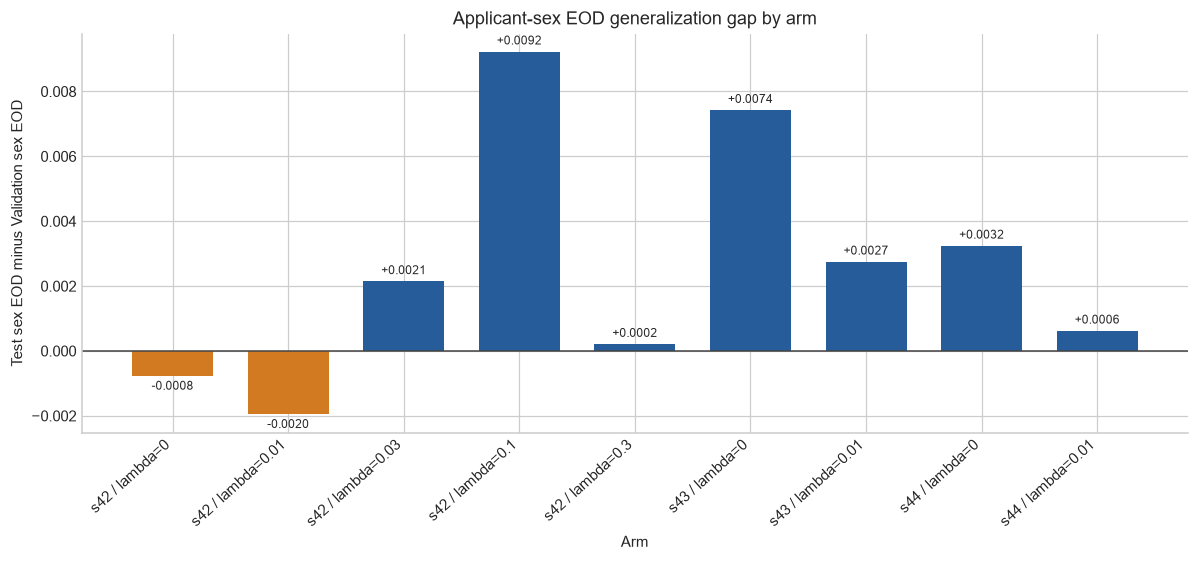

In [10]:
gaps = tables["sex_generalization_gaps.csv"].sort_values(["seed", "adversary_lambda"]).reset_index(drop=True)
display(gaps)
gaps["arm"] = gaps.apply(lambda row: f"s{int(row.seed)} / lambda={row.adversary_lambda:g}", axis=1)
colors = ["#255C99" if value >= 0 else "#D17A22" for value in gaps["test_minus_validation"]]
fig, ax = plt.subplots(figsize=(11, 5.2))
bars = ax.bar(gaps["arm"], gaps["test_minus_validation"], color=colors, width=0.7)
ax.axhline(0, color="#444444", linewidth=1)
ax.bar_label(bars, labels=[f"{value:+.4f}" for value in gaps["test_minus_validation"]], padding=3, fontsize=8)
ax.set(title="Applicant-sex EOD generalization gap by arm", xlabel="Arm", ylabel="Test sex EOD minus Validation sex EOD")
plt.xticks(rotation=42, ha="right")
plt.tight_layout()
plt.show()

## 10. Reconciliation checks

In [11]:
assert len(arm_metrics) == 18 and set(arm_metrics.groupby("partition").size()) == {9}
assert len(group_metrics) == 90 and set(group_metrics.groupby("partition").size()) == {45}
assert set(group_metrics["group"]) == set(ALL_GROUPS)
assert len(matched) == 6 and matched["valid"].all()
assert len(decision_changes) == 36
assert len(bootstrap_replicates) == 6000 and bootstrap_replicates["valid"].all()
assert len(bootstrap) == 6 and (bootstrap["valid_replicates"] == 1000).all() and (bootstrap["invalid_replicates"] == 0).all()
assert len(across_seed) == 3 and (across_seed["seed_count"] == 3).all()
assert len(gaps) == 9 and gaps["valid"].all()
assert set(arm_metrics.loc[arm_metrics["partition"] == "test", "rows"]) == {43996}
assert set(arm_metrics.loc[arm_metrics["partition"] == "validation", "rows"]) == {43995}
group_totals = group_metrics.groupby(["partition", "seed", "adversary_lambda"], as_index=False)["row_count"].sum()
assert set(group_totals.loc[group_totals["partition"] == "test", "row_count"]) == {43996}
assert set(group_totals.loc[group_totals["partition"] == "validation", "row_count"]) == {43995}
assert group_metrics.groupby(["partition", "group"])["row_count"].nunique().eq(1).all()
assert arm_metrics.groupby("partition")["record_id_sha256"].nunique().eq(1).all()
assert sorted(bootstrap_replicates["replicate_id"].unique()) == list(range(1000))
print("PASS: package integrity, lineage, table cardinalities, group coverage, replicate IDs, row totals, and stored validity flags reconcile.")

PASS: package integrity, lineage, table cardinalities, group coverage, replicate IDs, row totals, and stored validity flags reconcile.


## 11. Interpretation boundary

These outputs describe model behavior for the documented HMDA approval cohort. They do not establish causal effects, legal discrimination, legal compliance, creditworthiness, or default risk. A metric difference does not by itself determine whether mitigation is effective or preferable. Screening lambdas 0.03, 0.1, and 0.3 have one seed and therefore have no across-seed summary. Validation and Test reuse the already locked thresholds and saved predictions.

## 12. Research interpretation (user-owned)

Use the stored values above for the research narrative. The notebook intentionally does not assign an effectiveness label, select an arm, or make a methodological recommendation.